In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append('../')


from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch

from utils.custom_loader import custom_loader_training
from utils.mm_classifier import mm_classifier
from utils.custom_a_handles import custom_normalize, custom_to_tensor, custom_gauss_noise, custom_normalize99

#using albumentations library
import albumentations as A
#import albumentations.augmentations.functional as F
from albumentations.pytorch import ToTensorV2

# from utils.unet import UNet
from utils.unet import UNet, UNet_deep

from skimage import io
import cv2
import matplotlib.pyplot as plt
import numpy as np

from utils.load_files import getTrainingPairs

from sklearn.model_selection import train_test_split
import time, datetime

from utils.cell_aware_crop import CellAwareCrop

from main import train_net


/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/models/unetTB_400_260707_192912.pth
Number of phase images: 58
Number of binary masks : 58
unetTB_256_260707_192912.pth
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769
/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/models/unetTB_256_260707_192912.pth
training epoch 1
loss: 1.0082001050313314
training epoch 2
loss: 0.9708049972852071
training epoch 3
loss: 0.9465743660926819
training epoch 4
loss: 0.9243906696637472
training epoch 5
loss: 0.9480256358782451
training epoch 6
loss: 0.899362579981486
training epoch 7
loss: 0.903977906703949
training epoch 8
loss: 0.8881518880526225
training epoch 9
loss: 0.8816260695457458
training epoch 10
loss: 0.8767834901809692
training epoch 11
loss: 0.8625491698582967
training epoch 12
loss: 0.8751002271970113
training epoch 13
loss: 0.8573516925175985
training epoch 14
loss: 0.8591675241788228
training epoch 15
loss: 0.8507116874059041
training epoch 16
loss: 0.8455139994621277
training epoch 17
lo

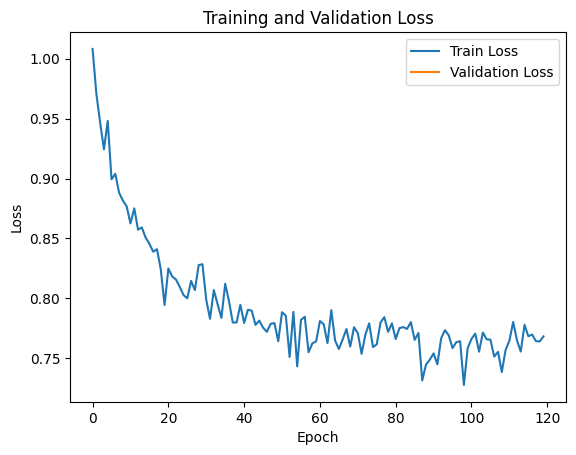

In [8]:
# Set training parameters
train_dirs =[
                #('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9767/KI_data_traps_cropped', ''),
                ('/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769/EXP-26-CF5404/chip_masks', ''),
                ]
save_dir = '/home/spartak/elflab/BSL3/analysis/EXP-26-CB9769'
net_size = 400
crop_window = 400
normalize = custom_normalize99
num_epochs = 120

#use albumentations library
training_transform = A.Compose(
    [   
        #A.RandomRotate90(p=1),
        #A.RandomCrop(crop_window, crop_window, p=1),
        CellAwareCrop(p=1,crop_size=crop_window, min_cell_fraction=0.05, max_attempts=20),
        A.GridDistortion(p=0.4),
        #A.ElasticTransform(p=0.4, alpha=50, sigma=20),
        A.Affine(p=0.8, translate_percent=(-0.2, 0.2), scale=(0.75, 1.25), rotate=(-5, 5)),
        A.GaussianBlur(p=0.6, blur_limit=0, sigma_limit=(0.1, 2.0)),
        A.Lambda(name='gauss-noise', image=custom_gauss_noise, p=0.5),
        A.GridDropout(p=0.3, ratio=0.3, random_offset=True),
        A.Lambda(name='normalize', image=normalize, p=1.0),
        A.Lambda(name='to_tensor', image=custom_to_tensor, mask=custom_to_tensor, p=1.0)
    ]
    )

ts = time.time()
ts = datetime.datetime.fromtimestamp(ts).strftime('%y%m%d_%H%M%S')
net_name = f'unetTB_{net_size}_'+ts+'.pth'
print(save_dir + "/models/" + net_name)


train_net(train_dirs,save_dir, net_size=256, training_transform=training_transform, num_epochs=num_epochs, normalize=normalize)
